In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    roc_auc_score,
    f1_score
)

In [124]:
from sklearn.datasets import load_breast_cancer
df = load_breast_cancer()
df = pd.DataFrame(
    df.data,
    columns=df.feature_names
)
df.head()
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='str')

In [125]:
from sklearn.datasets import load_breast_cancer

df = load_breast_cancer()

print(df.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [126]:
print(df.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [127]:
df.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [128]:
print(df.data.shape)
print(len(df.feature_names))
print(df.target.shape)

(569, 30)
30
(569,)


In [129]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer()

df = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

df["target"] = dataset.target

print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [130]:
X = df.drop("target", axis=1)

y = df["target"]

In [131]:
y.isnull().sum()

np.int64(0)

In [132]:
from sklearn.preprocessing import StandardScaler
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2, random_state=42)
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)

In [133]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
log=LogisticRegression()
dec=DecisionTreeClassifier(random_state=42)

In [134]:
dec.fit(X_train,y_train)
log.fit(X_train,y_train)
log_pred=log.predict(X_test)

e:\Python intern practice\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [135]:
#metrics
y_pred = dec.predict(X_test)
log_pred = log.predict(X_test)
accuracy1 = accuracy_score( y_test, y_pred)
accuracy2 = accuracy_score( y_test, log_pred)
confusion_matrix1 = confusion_matrix(y_test, y_pred)
roc_auc1 = roc_auc_score(y_test, y_pred)
roc_auc2 = roc_auc_score(y_test, log_pred)
f1_score1 = f1_score(y_test, y_pred)
f2_score2 = f1_score(y_test, log_pred)
report1 = classification_report(y_test, y_pred)
report2 = classification_report(y_test, log_pred)
print("Classification Report For Decision Tree:\n", report1)
print("Classification Report For Logistic Regression:\n", report2)
print("Confusion Matrix For Decision Tree:\n", confusion_matrix1)
print("ROC AUC For Decision Tree:", roc_auc1)
print("ROC AUC For Logistic Regression:", roc_auc2)
print("F1 Score For Decision Tree:", f1_score1)
print("F1 Score For Logistic Regression:", f2_score2) 
print("Accuracy For Decision Tree:", accuracy1)
print("Accuracy For Logistic Regression:", accuracy2)

Classification Report For Decision Tree:
               precision    recall  f1-score   support

           0       1.00      0.63      0.77        43
           1       0.82      1.00      0.90        71

    accuracy                           0.86       114
   macro avg       0.91      0.81      0.84       114
weighted avg       0.89      0.86      0.85       114

Classification Report For Logistic Regression:
               precision    recall  f1-score   support

           0       0.38      1.00      0.55        43
           1       0.00      0.00      0.00        71

    accuracy                           0.38       114
   macro avg       0.19      0.50      0.27       114
weighted avg       0.14      0.38      0.21       114

Confusion Matrix For Decision Tree:
 [[27 16]
 [ 0 71]]
ROC AUC For Decision Tree: 0.813953488372093
ROC AUC For Logistic Regression: 0.5
F1 Score For Decision Tree: 0.8987341772151899
F1 Score For Logistic Regression: 0.0
Accuracy For Decision Tree: 0.859

e:\Python intern practice\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
e:\Python intern practice\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
e:\Python intern practice\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\Python intern practice\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier

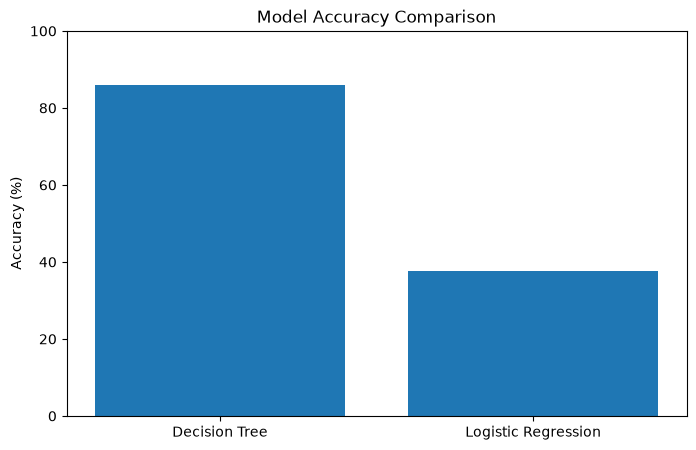

In [136]:
import matplotlib.pyplot as plt

models = ["Decision Tree", "Logistic Regression"]

accuracies = [
    accuracy1 * 100,
    accuracy2 * 100
]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [137]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model
log = LogisticRegression(max_iter=2000)

# Training
log.fit(X_train_scaled, y_train)

# Prediction
log_pred = log.predict(X_test_scaled)
    
# Evaluation
accuracy2 = accuracy_score(y_test, log_pred)

print("Logistic Regression Accuracy:", accuracy2)

Logistic Regression Accuracy: 0.37719298245614036


e:\Python intern practice\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [138]:
print("Actual values:")
print(y_test.value_counts())

print("\nPredicted values:")
print(pd.Series(log_pred).value_counts())

Actual values:
target
1    71
0    43
Name: count, dtype: int64

Predicted values:
0    114
Name: count, dtype: int64


In [139]:
print(log.coef_)
print(log.intercept_)
print(log.n_iter_)

[[-0.43190368 -0.38732553 -0.39343248 -0.46521006 -0.07166728  0.54016395
  -0.8014581  -1.11980408  0.23611852  0.07592093 -1.26817815  0.18887738
  -0.61058302 -0.9071857  -0.31330675  0.68249145  0.17527452 -0.3112999
   0.50042502  0.61622993 -0.87984024 -1.35060559 -0.58945273 -0.84184594
  -0.54416967  0.01611019 -0.94305313 -0.77821726 -1.20820031 -0.15741387]]
[0.44558453]
[20]


In [140]:
print("Actual values:")
print(y_test.value_counts())

print("\nPredicted values:")
print(pd.Series(log_pred).value_counts())

Actual values:
target
1    71
0    43
Name: count, dtype: int64

Predicted values:
0    114
Name: count, dtype: int64
